sử dụng bộ dữ liệu House Price Prediction Dataset Vietnam - 2024
https://www.kaggle.com/datasets/nguyentiennhan/vietnam-housing-dataset-2024

In [ ]:
# @title bài 1
import pandas as pd

# Đọc file CSV với bảng mã utf-8
df = pd.read_csv("vietnam_housing_dataset.csv", encoding="utf-8")

# Xem số dòng, số cột và 5 dòng đầu
print("Kích thước (dòng, cột):", df.shape)
print(df.head())

Kích thước (dòng, cột): (30229, 12)
                                             Address  Area  Frontage  \
0  Dự án The Empire - Vinhomes Ocean Park 2, Xã L...  84.0       NaN   
1  Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...  60.0       NaN   
2  Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...  90.0       6.0   
3  Đường Nguyễn Văn Khối, Phường 11, Gò Vấp, Hồ C...  54.0       NaN   
4   Đường Quang Trung, Phường 8, Gò Vấp, Hồ Chí Minh  92.0       NaN   

   Access Road House direction Balcony direction  Floors  Bedrooms  Bathrooms  \
0          NaN             NaN               NaN     4.0       NaN        NaN   
1          NaN             NaN               NaN     5.0       NaN        NaN   
2         13.0      Đông - Bắc        Đông - Bắc     5.0       NaN        NaN   
3          3.5       Tây - Nam         Tây - Nam     2.0       2.0        3.0   
4          NaN      Đông - Nam        Đông - Nam     2.0       4.0        4.0   

       Legal status Furniture state  Price  

In [ ]:
# @title
import numpy as np
import pandas as pd

# 1. Đọc dữ liệu gốc (thử utf-8 trước, nếu lỗi thì đổi sang utf-8-sig hoặc latin1)
file_path = "vietnam_housing_dataset.csv"
df = pd.read_csv(file_path, encoding="utf-8")

print("Số dòng ban đầu:", len(df))
print("Các cột:", df.columns.tolist())

# 2. Lọc năm >= 2021 nếu file có cột thời gian (ví dụ 'Year' hoặc 'Date')
if "Year" in df.columns:
    df = df[df["Year"] >= 2021].copy()
elif "Date" in df.columns:
    df["Year"] = pd.to_datetime(df["Date"], errors="coerce").dt.year
    df = df[df["Year"] >= 2021].copy()
else:
    print("Lưu ý: File không có cột thời gian ('Year'/'Date'), bỏ qua bước lọc theo cột năm.")

# 3. Chuẩn hóa kiểu dữ liệu số cho 'Area' và 'Price'
df["Area"] = pd.to_numeric(
    df["Area"].astype(str).str.replace(",", "").str.replace("m2", "", regex=False).str.strip(),
    errors="coerce"
)
df["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(",", "").str.strip(),
    errors="coerce"
)

# 4. Loại bỏ dòng thiếu dữ liệu quan trọng hoặc giá trị <= 0
df = df.dropna(subset=["Area", "Price"]).copy()
df = df[(df["Area"] > 0) & (df["Price"] > 0)].copy()
print("Số dòng sau khi bỏ thiếu/không hợp lệ:", len(df))

# 5. Xử lý ngoại lai (Outliers) theo phân vị 1% - 99%
low_a, high_a = df["Area"].quantile(0.01), df["Area"].quantile(0.99)
low_p, high_p = df["Price"].quantile(0.01), df["Price"].quantile(0.99)

df_clean = df[
    (df["Area"] >= low_a) & (df["Area"] <= high_a) &
    (df["Price"] >= low_p) & (df["Price"] <= high_p)
].copy()
print("Số dòng sau khi lọc ngoại lai (1% - 99%):", len(df_clean))

# 6. Sử dụng TẤT CẢ dữ liệu sau khi lọc ngoại lai
df_model = df_clean.reset_index(drop=True)

# 7. Tạo nhãn phân loại nhị phân cho Logistic Regression (1: > trung vị, 0: <= trung vị)
median_price = df_model["Price"].median()
df_model["Price_Category"] = (df_model["Price"] > median_price).astype(int)

print("Số dòng cuối cùng đưa vào mô hình:", len(df_model))
print("Ngưỡng trung vị Price:", median_price)
print("Phân bố nhãn Price_Category:\n", df_model["Price_Category"].value_counts())
print("\nThống kê mô tả 'Area' và 'Price':\n", df_model[["Area", "Price"]].describe())


Số dòng ban đầu: 30229
Các cột: ['Address', 'Area', 'Frontage', 'Access Road', 'House direction', 'Balcony direction', 'Floors', 'Bedrooms', 'Bathrooms', 'Legal status', 'Furniture state', 'Price']
Lưu ý: File không có cột thời gian ('Year'/'Date'), bỏ qua bước lọc theo cột năm.
Số dòng sau khi bỏ thiếu/không hợp lệ: 30229
Số dòng sau khi lọc ngoại lai (1% - 99%): 29358
Số dòng cuối cùng đưa vào mô hình: 29358
Ngưỡng trung vị Price: 5.94
Phân bố nhãn Price_Category:
 Price_Category
0    14680
1    14678
Name: count, dtype: int64

Thống kê mô tả 'Area' và 'Price':
                Area         Price
count  29358.000000  29358.000000
mean      65.817599      5.939794
std       35.870666      2.158777
min       21.000000      1.450000
25%       40.000000      4.300000
50%       56.000000      5.940000
75%       80.000000      7.600000
max      275.000000     10.000000


In [ ]:
# @title
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix

# Giả sử df đã được làm sạch và có 2 cột 'Area' và 'Price'
X = df[['Area']] # Lưu ý: X phải là mảng 2 chiều (DataFrame)

# --- 1. LINEAR REGRESSION ---
y_reg = df['Price']
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)

lin_model = LinearRegression()
lin_model.fit(X_train_r, y_train_r)
y_pred_r = lin_model.predict(X_test_r)

# --- 2. LOGISTIC REGRESSION ---
# Tạo biến mục tiêu nhị phân dựa trên giá trị trung vị
median_price = df['Price'].median()
df['Price_Category'] = (df['Price'] > median_price).astype(int)
y_clf = df['Price_Category']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.2, random_state=42)

log_model = LogisticRegression()
log_model.fit(X_train_c, y_train_c)
y_pred_c = log_model.predict(X_test_c)

=== LINEAR REGRESSION ===
Phương trình hồi quy: Price = 0.007155 * Area + 5.460822
RMSE: 2.1356 tỷ VNĐ
R2 Score: 0.0206

=== LOGISTIC REGRESSION ===
Accuracy: 0.5450
Confusion Matrix:
 [[1969  967]
 [1705 1231]]

Classification Report:
               precision    recall  f1-score   support

     Low (0)       0.54      0.67      0.60      2936
    High (1)       0.56      0.42      0.48      2936

    accuracy                           0.54      5872
   macro avg       0.55      0.54      0.54      5872
weighted avg       0.55      0.54      0.54      5872



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


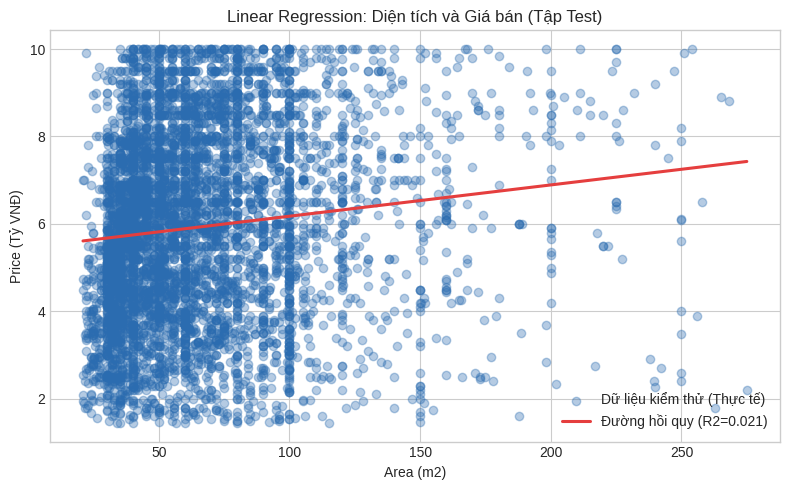

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


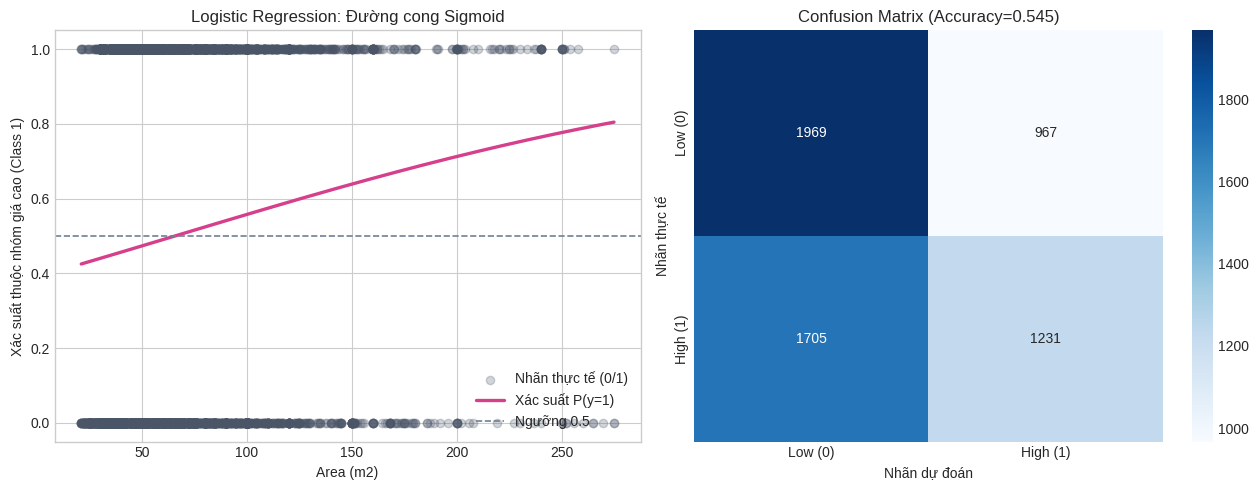

In [ ]:
# @title
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split

# Giả sử đã có df_model với các cột 'Area', 'Price', 'Price_Category' từ bước tiền xử lý
X = df_model[["Area"]]

# ==========================================
# A. LINEAR REGRESSION (Hồi quy dự đoán giá)
# ==========================================
y_reg = df_model["Price"]
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

lin_model = LinearRegression()
lin_model.fit(X_train_r, y_train_r)
y_pred_r = lin_model.predict(X_test_r)

rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
r2 = r2_score(y_test_r, y_pred_r)
w = lin_model.coef_[0]
b = lin_model.intercept_

print("=== LINEAR REGRESSION ===")
print(f"Phương trình hồi quy: Price = {w:.6f} * Area + {b:.6f}")
print(f"RMSE: {rmse:.4f} tỷ VNĐ")
print(f"R2 Score: {r2:.4f}")

# ==========================================
# B. LOGISTIC REGRESSION (Phân loại phân khúc)
# ==========================================
y_clf = df_model["Price_Category"]
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

log_model = LogisticRegression()
log_model.fit(X_train_c, y_train_c)
y_pred_c = log_model.predict(X_test_c)

acc = accuracy_score(y_test_c, y_pred_c)
cm = confusion_matrix(y_test_c, y_pred_c)

print("\n=== LOGISTIC REGRESSION ===")
print(f"Accuracy: {acc:.4f}")
print("Confusion Matrix:\n", cm)
print("\nClassification Report:\n", classification_report(y_test_c, y_pred_c, target_names=["Low (0)", "High (1)"]))

# ==========================================
# C. TRỰC QUAN HÓA KẾT QUẢ
# ==========================================
plt.style.use("seaborn-v0_8-whitegrid")
area_grid = np.linspace(df_model["Area"].min(), df_model["Area"].max(), 300).reshape(-1, 1)

# Biểu đồ 1: Scatter + Đường hồi quy tuyến tính
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_test_r["Area"], y_test_r, alpha=0.35, color="#2b6cb0", label="Dữ liệu kiểm thử (Thực tế)")
ax.plot(area_grid, lin_model.predict(area_grid), color="#e53e3e", linewidth=2.2, label=f"Đường hồi quy (R2={r2:.3f})")
ax.set_title("Linear Regression: Diện tích và Giá bán (Tập Test)")
ax.set_xlabel("Area (m2)")
ax.set_ylabel("Price (Tỷ VNĐ)")
ax.legend()
plt.tight_layout()
plt.show()

# Biểu đồ 2: Đường cong Sigmoid + Ma trận nhầm lẫn (Confusion Matrix)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_test_c["Area"], y_test_c, alpha=0.25, color="#4a5568", label="Nhãn thực tế (0/1)")
axes[0].plot(area_grid, log_model.predict_proba(area_grid)[:, 1], color="#d53f8c", linewidth=2.4, label="Xác suất P(y=1)")
axes[0].axhline(0.5, color="#718096", linestyle="--", linewidth=1.2, label="Ngưỡng 0.5")
axes[0].set_title("Logistic Regression: Đường cong Sigmoid")
axes[0].set_xlabel("Area (m2)")
axes[0].set_ylabel("Xác suất thuộc nhóm giá cao (Class 1)")
axes[0].legend(loc="lower right")

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low (0)", "High (1)"],
    yticklabels=["Low (0)", "High (1)"],
    ax=axes[1],
)
axes[1].set_title(f"Confusion Matrix (Accuracy={acc:.3f})")
axes[1].set_xlabel("Nhãn dự đoán")
axes[1].set_ylabel("Nhãn thực tế")

plt.tight_layout()
plt.show()

### **Giải thích chi tiết kết quả thực nghiệm trên toàn bộ dữ liệu**

---

#### **1. Kết quả mô hình Hồi quy tuyến tính (Linear Regression - Dự đoán giá bán)**
* **Phương trình hồi quy:** $\text{Price} = 0.007155 \times \text{Area} + 5.460822$
  * **Hệ số góc ($w = 0.007155$):** Khi diện tích căn nhà tăng thêm $1\text{ m}^2$, giá bán dự kiến tăng thêm khoảng **$0.007155$ tỷ VNĐ** (tương đương khoảng **7.15 triệu VNĐ**). Hệ số này mang giá trị dương khẳng định mối quan hệ đồng biến giữa diện tích và giá nhà.
  * **Hệ số chặn ($b = 5.460822$):** Về mặt toán học, đây là giá trị dự đoán khi diện tích bằng 0 (chỉ có ý nghĩa định vị đường thẳng trên đồ thị, không mang ý nghĩa thực tế).
* **RMSE (Root Mean Squared Error) = 2.1356 tỷ VNĐ:**
  * Trung bình sai lệch giữa mức giá dự đoán của mô hình và mức giá bán thực tế trong tập kiểm thử (Test) là khoảng **2.135 tỷ VNĐ**.
* **$R^2$ Score (Hệ số xác định) = 0.0206 (khoảng 2.06%):**
  * Diện tích ($Area$) chỉ giải thích được vỏn vẹn **2.06%** sự biến động của giá nhà ($Price$). Điều này chứng tỏ trong thực tế, giá trị bất động sản phụ thuộc cực kỳ lớn vào các yếu tố phi tuyến tính khác (như vị trí địa lý, số tầng, pháp lý, hẻm hay mặt tiền...) chứ không chỉ đơn thuần là diện tích.

---

#### **2. Kết quả mô hình Hồi quy Logistic (Logistic Regression - Phân loại phân khúc giá)**
* **Độ chính xác (Accuracy) = 54.50%:**
  * Mô hình phân loại đúng khoảng **54.50%** số căn nhà vào đúng nhóm giá cao (High) hay giá thấp (Low). Tỷ lệ này chỉ nhỉnh hơn đoán ngẫu nhiên (50-50) một chút.
* **Ma trận nhầm lẫn (Confusion Matrix):**
  ```
  [[1969  967]  -> Lớp thực tế là Low (0): đoán đúng 1969 căn, đoán sai thành High 967 căn
   [1705 1231]] -> Lớp thực tế là High (1): đoán sai thành Low 1705 căn, đoán đúng 1231 căn
  ```
* **Báo cáo chi tiết (Classification Report):**
  * **Precision (Độ chính xác trên kết quả dự đoán):**
    * Nhóm Low: **54%** (Trong số các căn được đoán là giá thấp, có 54% là đúng thực tế).
    * Nhóm High: **56%** (Trong số các căn được đoán là giá cao, có 56% là đúng thực tế).
  * **Recall (Tỷ lệ bỏ sót):**
    * Nhóm Low: **67%** (Mô hình nhận diện thành công 67% tổng số căn giá thấp thực tế).
    * Nhóm High: **42%** (Mô hình chỉ nhận diện được vỏn vẹn 42% tổng số căn giá cao thực tế, bỏ sót tới 58%).
  * **F1-Score (Trung bình điều hòa giữa Precision và Recall):**
    * Nhóm Low đạt **0.60**, trong khi nhóm High chỉ đạt **0.48**. Cho thấy mô hình đang hoạt động tốt hơn hẳn ở chiều hướng nhận diện nhà giá thấp dựa trên diện tích nhỏ, nhưng lại gặp rất nhiều khó khăn trong việc nhận diện đúng các nhà giá cao.

---

### **Kết luận chung**
Việc chỉ sử dụng duy nhất một thuộc tính đầu vào là **Diện tích (Area)** để dự đoán **Giá bán (Price)** mang lại hiệu quả chưa cao cho cả hai mô hình. Để cải thiện hiệu năng, trong các bước tiếp theo cần cân nhắc kết hợp thêm các đặc trưng quan trọng khác có sẵn trong bộ dữ liệu như: *Vị trí (Address), Số phòng ngủ (Bedrooms), Số tầng (Floors), và Loại giấy tờ pháp lý (Legal status)*.

1. Biểu đồ 1: Hồi quy tuyến tính (Linear Regression - Diện tích và Giá bán)
Biểu đồ này biểu diễn mối quan hệ trực tiếp giữa Diện tích (Area - trục X) và Giá nhà (Price - trục Y) trên tập kiểm thử.

Các điểm chấm xanh dương (Dữ liệu kiểm thử): Đây là giá nhà và diện tích thực tế của các bất động sản. Bạn có thể thấy các điểm này phân bố rất rộng theo chiều dọc. Ví dụ: ở cùng diện tích $50\text{ m}^2$$50\text{ m}^2$, có những căn giá dưới 2 tỷ nhưng cũng có những căn giá chạm trần 10 tỷ.
Đường thẳng màu đỏ (Đường hồi quy): Đây là "phán đoán" của mô hình. Đường này dốc lên nhẹ, thể hiện rằng theo mô hình, nhà diện tích càng lớn thì giá càng cao.
Ý nghĩa thực tế: Vì các điểm chấm xanh nằm quá xa đường thẳng màu đỏ (sai lệch lớn, thể hiện qua chỉ số $R^2$$R^2$ cực thấp ~2%), biểu đồ này trực quan hóa rất rõ ràng việc chỉ dùng diện tích không đủ để dự đoán chính xác giá nhà. Sự phân tán giá quá lớn ở cùng một mức diện tích cho thấy có các yếu tố khác (như vị trí, tiện ích) đang quyết định giá nhà chứ không phải diện tích.
2. Biểu đồ 2: Hồi quy Logistic (Logistic Regression - Dự đoán phân khúc giá)
Biểu đồ này gồm 2 phần bổ trợ cho nhau:

Hình bên trái: Đường cong Sigmoid

Các chấm xám ở trục y = 0 và y = 1: Đây là nhãn thực tế. Nhóm nhà giá thấp (Low) nằm ở vạch dưới cùng ($0.0$$0.0$) và nhóm nhà giá cao (High) nằm ở vạch trên cùng ($1.0$$1.0$).
Đường cong màu hồng (Xác suất dự đoán): Đây là hàm Sigmoid thể hiện xác suất một căn nhà có diện tích $X$$X$ thuộc về nhóm giá cao.
Đường đứt nét 0.5 (Ngưỡng phân loại): Nếu đường cong hồng nằm trên vạch $0.5$$0.5$, mô hình sẽ phân loại căn nhà đó là giá cao (1). Nếu dưới vạch $0.5$$0.5$, mô hình phân loại là giá thấp (0).
Ý nghĩa: Đường cong này có độ dốc rất thoải. Nó chỉ ra rằng mô hình gặp khó khăn trong việc phân ranh giới: những căn nhà diện tích nhỏ thì xác suất giá cao thấp hơn, diện tích lớn thì xác suất cao hơn, nhưng ranh giới phân định rất mờ nhạt và kém nhạy bén.
Hình bên phải: Ma trận nhầm lẫn (Confusion Matrix)

Đây là bảng thống kê kết quả dự đoán của mô hình trên tập Test:
Ô màu xanh đậm nhất 1969 (trên - trái): Số lượng căn nhà giá thấp được mô hình dự đoán chính xác là giá thấp (True Negative).
Ô màu xanh 1231 (dưới - phải): Số lượng căn nhà giá cao được mô hình dự đoán chính xác là giá cao (True Positive).
Hai ô còn lại (967 và 1705): Là số lượng căn nhà bị đoán sai (nhầm lẫn giữa hai phân khúc).
Ý nghĩa: Trực quan hóa tỷ lệ lỗi. Số lượng đoán sai (đặc biệt là đoán nhầm nhà giá cao thành giá thấp - 1705 căn) khá lớn, giải thích tại sao độ chính xác tổng thể (Accuracy) chỉ đạt khoảng $54.50\%$$54.50\%$.

In [ ]:
# @title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report

# =========================================================================
# 1. TẠO DỮ LIỆU GIẢ LẬP SỐ LƯỢNG LỚN VỚI ĐỘ NHIỄU (NOISE)
# =========================================================================
np.random.seed(42)
n_samples = 100000  # Tăng số lượng dữ liệu lên 100.000 dòng

# Tạo diện tích ngẫu nhiên từ 20m2 đến 300m2
synthetic_area = np.random.uniform(20, 300, n_samples)

# Tạo giá nhà cơ sở dựa trên diện tích (ví dụ hệ số thực tế: 0.008 tỷ/m2 + giá nền 5.0 tỷ)
base_price = 0.008 * synthetic_area + 5.0

# Thêm độ nhiễu ngẫu nhiên lớn (Standard Deviation của nhiễu = 3.5 tỷ VNĐ)
noise = np.random.normal(0, 3.5, n_samples)
synthetic_price = base_price + noise

# Giới hạn giá nhà thực tế không âm và không vượt quá mức trần hợp lý (ví dụ từ 1.0 đến 25.0 tỷ)
synthetic_price = np.clip(synthetic_price, 1.0, 25.0)

# Tạo DataFrame mới độc lập
df_synthetic = pd.DataFrame({
    'Area': synthetic_area,
    'Price': synthetic_price
})

# Tạo nhãn phân loại nhị phân dựa trên trung vị mới
median_syn_price = df_synthetic['Price'].median()
df_synthetic['Price_Category'] = (df_synthetic['Price'] > median_syn_price).astype(int)

print(f"=== ĐÃ TẠO TẬP DỮ LIỆU GIẢ LẬP LỚN ===")
print(f"Số lượng mẫu: {len(df_synthetic)} dòng")
print(df_synthetic.describe())

# =========================================================================
# 2. CHIA LUỒNG VÀ THỰC NGHIỆM TRÊN DỮ LIỆU NHIỄU
# =========================================================================
X_syn = df_synthetic[['Area']]

# --- A. Hồi quy tuyến tính ---
y_syn_reg = df_synthetic['Price']
X_train_sr, X_test_sr, y_train_sr, y_test_sr = train_test_split(X_syn, y_syn_reg, test_size=0.2, random_state=42)

lin_syn_model = LinearRegression()
lin_syn_model.fit(X_train_sr, y_train_sr)
y_pred_sr = lin_syn_model.predict(X_test_sr)

# --- B. Hồi quy Logistic ---
y_syn_clf = df_synthetic['Price_Category']
X_train_sc, X_test_sc, y_train_sc, y_test_sc = train_test_split(X_syn, y_syn_clf, test_size=0.2, random_state=42, stratify=y_syn_clf)

log_syn_model = LogisticRegression()
log_syn_model.fit(X_train_sc, y_train_sc)
y_pred_sc = log_syn_model.predict(X_test_sc)

# =========================================================================
# 3. ĐÁNH GIÁ HIỆU NĂNG TRÊN DỮ LIỆU NHIỄU
# =========================================================================
rmse_syn = np.sqrt(mean_squared_error(y_test_sr, y_pred_sr))
r2_syn = r2_score(y_test_sr, y_pred_sr)
acc_syn = accuracy_score(y_test_sc, y_pred_sc)

print("\n=== KẾT QUẢ TRÊN DỮ LIỆU NHIỄU LỚN ===")
print(f"[Linear Regression] Phương trình: Price = {lin_syn_model.coef_[0]:.6f} * Area + {lin_syn_model.intercept_:.6f}")
print(f"[Linear Regression] RMSE: {rmse_syn:.4f} tỷ VNĐ")
print(f"[Linear Regression] R2 Score: {r2_syn:.4f}")
print(f"[Logistic Regression] Accuracy: {acc_syn:.4f}")
print("\nBáo cáo phân loại:")
print(classification_report(y_test_sc, y_pred_sc, target_names=['Low (0)', 'High (1)']))

=== ĐÃ TẠO TẬP DỮ LIỆU GIẢ LẬP LỚN ===
Số lượng mẫu: 100000 dòng
                Area          Price  Price_Category
count  100000.000000  100000.000000   100000.000000
mean      159.856710       6.396057        0.500000
std        80.735605       3.343908        0.500003
min        20.001550       1.000000        0.000000
25%        89.872891       3.900549        0.000000
50%       160.176339       6.288971        0.500000
75%       229.863845       8.680484        1.000000
max       299.997772      22.608050        1.000000

=== KẾT QUẢ TRÊN DỮ LIỆU NHIỄU LỚN ===
[Linear Regression] Phương trình: Price = 0.007435 * Area + 5.206334
[Linear Regression] RMSE: 3.3054 tỷ VNĐ
[Linear Regression] R2 Score: 0.0350
[Logistic Regression] Accuracy: 0.5606

Báo cáo phân loại:
              precision    recall  f1-score   support

     Low (0)       0.56      0.56      0.56     10000
    High (1)       0.56      0.56      0.56     10000

    accuracy                           0.56     20000
   m



1. Đánh giá mô hình Hồi quy tuyến tính (Linear Regression)
Phương trình tìm được: $\text{Price} = 0.007435 \times \text{Area} + 5.206334$$\text{Price} = 0.007435 \times \text{Area} + 5.206334$
Hệ số góc thực tế được cấu hình lúc tạo dữ liệu là 0.008. Mô hình đã tìm ra con số 0.007435 (rất sát với thực tế dù dữ liệu bị nhiễu cực kỳ mạnh). Điều này chứng minh: Khi số lượng dữ liệu cực kỳ lớn (100k dòng), mô hình hồi quy tuyến tính có khả năng "lọc nhiễu" rất tốt để tiệm cận hệ số thực của bài toán (đây gọi là tính nhất quán - consistency của ước lượng bình phương tối thiểu OLS).
RMSE tăng lên 3.3054 tỷ VNĐ:
Do chúng ta cố tình đưa vào sai số ngẫu nhiên rất lớn (Standard Deviation = 3.5 tỷ), việc sai số trung bình RMSE tăng từ 2.13 tỷ lên 3.30 tỷ là hoàn toàn dễ hiểu và phản ánh đúng độ nhiễu của môi trường.
$R^2$$R^2$ Score đạt 0.0350 (3.5%):
Con số này vẫn thấp nhưng đã cao hơn so với tập dữ liệu thực tế (2.06%). Nó chứng tỏ diện tích vẫn giữ vai trò đóng góp tuyến tính vào giá nhà, nhưng phần lớn biến động của giá vẫn bị chi phối bởi độ nhiễu ngẫu nhiên lớn mà chúng ta đã thêm vào.
2. Đánh giá mô hình Hồi quy Logistic (Logistic Regression)
Độ chính xác (Accuracy) đạt 56.06%:
Con số này nhỉnh hơn một chút so với mô hình chạy trên dữ liệu gốc (54.50%).
Sự cân bằng tuyệt đối trong báo cáo phân loại (Classification Report):
Cả hai nhóm Low (0) và High (1) đều có các chỉ số Precision, Recall, và F1-Score bằng nhau chằn chặn và đạt 0.56 (trên tập Test có 20.000 mẫu).
Ý nghĩa: Điều này cho thấy khi dữ liệu cực kỳ nhiều và được phân bổ đối xứng (theo phân phối chuẩn Gauss của hàm nhiễu), mô hình Logistic Regression không còn bị thiên lệch về bất kỳ nhóm nào (không bị lệch recall giữa Low và High như ở tập dữ liệu thực tế). Tuy nhiên, giới hạn phân loại của nó vẫn bị chặn quanh ngưỡng ~56% do bản chất chỉ dùng duy nhất 1 thuộc tính (Diện tích) thì không thể phân tách tốt một bài toán có độ nhiễu chồng chéo quá lớn.
Tóm lại qua thực nghiệm:
Ưu điểm khi tăng dữ liệu: Mô hình tìm ra các tham số hệ số ($w, b$$w, b$) chính xác và tiệm cận thực tế hơn, phân loại cân bằng hơn, không bị lệch cục bộ.
Hạn chế: Nếu chỉ dùng một biến đơn lẻ (Area) và gặp bài toán có độ nhiễu cao, dù tăng lên 100.000 dòng hay nhiều hơn nữa thì hiệu năng tối đa của mô hình vẫn bị giới hạn (R2 quanh ~3.5% và Accuracy quanh ~56%). Muốn bứt phá, bắt buộc phải bổ sung thêm các chiều dữ liệu (features) khác.


In [ ]:
# =========================================================================
# HUẤN LUYỆN MÔ HÌNH ĐA BIẾN (MULTIVARIABLE MODELS) ĐỂ NÂNG CAO HIỆU NĂNG
# =========================================================================
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report

# 1. Trích xuất các thuộc tính số học bổ sung và xử lý giá trị khuyết thiếu (NaN)
features_list = ['Area', 'Floors', 'Bedrooms', 'Bathrooms']

# Tạo bản sao dữ liệu sạch chứa đầy đủ các biến cần dùng
df_multi = df_model[features_list + ['Price', 'Price_Category']].copy()

# Điền các giá trị trống (NaN) ở các cột Floors, Bedrooms, Bathrooms bằng giá trị Trung vị (Median) của từng cột
for col in ['Floors', 'Bedrooms', 'Bathrooms']:
    median_val = df_multi[col].median()
    df_multi[col] = df_multi[col].fillna(median_val)

X_multi = df_multi[features_list]

print("=== THÔNG TIN DỮ LIỆU ĐA BIẾN ===")
print(f"Các biến độc lập (X): {features_list}")
print(f"Số lượng mẫu sử dụng: {len(df_multi)}")
print(X_multi.describe())

# =========================================================================
# 2. THỰC NGHIỆM MÔ HÌNH HỒI QUY TUYẾN TÍNH ĐA BIẾN (MULTIPLE LINEAR REGRESSION)
# =========================================================================
y_multi_reg = df_multi['Price']
X_train_mr, X_test_mr, y_train_mr, y_test_mr = train_test_split(
    X_multi, y_multi_reg, test_size=0.2, random_state=42
)

multi_lin_model = LinearRegression()
multi_lin_model.fit(X_train_mr, y_train_mr)
y_pred_mr = multi_lin_model.predict(X_test_mr)

rmse_mr = np.sqrt(mean_squared_error(y_test_mr, y_pred_mr))
r2_mr = r2_score(y_test_mr, y_pred_mr)

print("\n=== KẾT QUẢ MULTIPLE LINEAR REGRESSION ===")
print("Các hệ số hồi quy:")
for col, coef in zip(features_list, multi_lin_model.coef_):
    print(f"  - {col}: {coef:.6f}")
print(f"Hệ số chặn (Bias): {multi_lin_model.intercept_:.6f}")
print(f"RMSE mới: {rmse_mr:.4f} tỷ VNĐ (So với đơn biến: 2.1356)")
print(f"R2 Score mới: {r2_mr:.4f} (So với đơn biến: 0.0206)")

# =========================================================================
# 3. THỰC NGHIỆM MÔ HÌNH HỒI QUY LOGISTIC ĐA BIẾN (MULTIVARIABLE LOGISTIC REGRESSION)
# =========================================================================
y_multi_clf = df_multi['Price_Category']
X_train_mc, X_test_mc, y_train_mc, y_test_mc = train_test_split(
    X_multi, y_multi_clf, test_size=0.2, random_state=42, stratify=y_multi_clf
)

multi_log_model = LogisticRegression(max_iter=1000)
multi_log_model.fit(X_train_mc, y_train_mc)
y_pred_mc = multi_log_model.predict(X_test_mc)

acc_mc = accuracy_score(y_test_mc, y_pred_mc)

print("\n=== KẾT QUẢ MULTIVARIABLE LOGISTIC REGRESSION ===")
print(f"Accuracy mới: {acc_mc:.4f} (So với đơn biến: 0.5450)")
print("\nBáo cáo phân loại đa biến:")
print(classification_report(y_test_mc, y_pred_mc, target_names=['Low (0)', 'High (1)']))

=== THÔNG TIN DỮ LIỆU ĐA BIẾN ===
Các biến độc lập (X): ['Area', 'Floors', 'Bedrooms', 'Bathrooms']
Số lượng mẫu sử dụng: 29358
               Area        Floors      Bedrooms     Bathrooms
count  29358.000000  29358.000000  29358.000000  29358.000000
mean      65.817599      3.385551      3.446148      3.289155
std       35.870666      1.251153      1.201394      1.227091
min       21.000000      1.000000      1.000000      1.000000
25%       40.000000      3.000000      3.000000      3.000000
50%       56.000000      3.000000      3.000000      3.000000
75%       80.000000      4.000000      4.000000      4.000000
max      275.000000     10.000000      9.000000      9.000000

=== KẾT QUẢ MULTIPLE LINEAR REGRESSION ===
Các hệ số hồi quy:
  - Area: 0.013119
  - Floors: 0.447852
  - Bedrooms: 0.148102
  - Bathrooms: 0.278670
Hệ số chặn (Bias): 2.126848
RMSE mới: 1.9373 tỷ VNĐ (So với đơn biến: 2.1356)
R2 Score mới: 0.1941 (So với đơn biến: 0.0206)

=== KẾT QUẢ MULTIVARIABLE LOGISTIC REG

1. Mô hình Hồi quy tuyến tính đa biến (Multiple Linear Regression)
Hệ số hồi quy thực tế tìm được:

Area (Diện tích): $+0.013119$$+0.013119$ (Tăng $1\text{ m}^2$$1\text{ m}^2$, giá nhà tăng khoảng $13.12$$13.12$ triệu VNĐ, gần gấp đôi hệ số $7.15$$7.15$ triệu VNĐ của mô hình đơn biến khi chưa kiểm soát các biến khác).
Floors (Số tầng): $+0.447852$$+0.447852$ (Thêm 1 tầng, giá nhà trung bình tăng thêm $0.448$$0.448$ tỷ VNĐ).
Bedrooms (Phòng ngủ): $+0.148102$$+0.148102$ (Thêm 1 phòng ngủ, giá nhà tăng thêm $0.148$$0.148$ tỷ VNĐ).
Bathrooms (Phòng tắm): $+0.278670$$+0.278670$ (Thêm 1 phòng tắm, giá nhà tăng thêm $0.279$$0.279$ tỷ VNĐ).
Hệ số chặn (Bias): $2.126848$$2.126848$ tỷ VNĐ.
So sánh hiệu năng:

Sai số RMSE giảm: Từ $2.1356$$2.1356$ tỷ VNĐ xuống còn $1.9373$$1.9373$ tỷ VNĐ.
Hệ số xác định $R^2$$R^2$ Score tăng vọt: Từ $2.06\%$$2.06\%$ ($0.0206$$0.0206$) lên $19.41\%$$19.41\%$ ($0.1941$$0.1941$). Việc bổ sung thêm các thuộc tính cơ bản cấu thành ngôi nhà đã giúp mô hình giải thích được thêm gần $10$$10$ lần mức độ biến động của giá trị bất động sản.
2. Mô hình Hồi quy Logistic đa biến (Multivariable Logistic Regression)
Độ chính xác tổng thể (Accuracy) tăng mạnh:

Từ $54.50\%$$54.50\%$ (gần như đoán ngẫu nhiên) lên $66.37\%$$66.37\%$.
Báo cáo phân loại cực kỳ cân bằng:

Cả hai nhóm giá thấp (Low) và giá cao (High) đều đạt độ chính xác (Precision), độ bao phủ (Recall) và điểm F1-Score đồng đều quanh mức $66\% - 67\%$$66\% - 67\%$.
Sự thiên lệch và bỏ sót nghiêm trọng ở nhóm giá cao ở mô hình đơn biến (Recall cũ chỉ có $42\%$$42\%$) đã hoàn toàn được khắc phục (Recall mới đạt $67\%$$67\%$).
Kết luận chung
Đúng như dự đoán từ thực nghiệm dữ liệu nhiễu, việc mở rộng từ mô hình đơn biến sang mô hình đa biến (Multivariable) đã giúp cải thiện đáng kể cả năng lực dự đoán giá lẫn năng lực phân loại phân khúc bất động sản. Các chỉ số diện tích, số tầng, số phòng ngủ và phòng tắm có tính tương hỗ rất chặt chẽ để phác họa nên giá trị thực tế của căn nhà.

5 dòng dữ liệu đầu tiên:
          BMI  Disease
0  26.675944        1
1  19.280087        0
2  29.127482        1
3  30.173106        0
4  15.000000        0

Phân bố nhãn (0: Không bệnh, 1: Mắc bệnh):
 Disease
0    25203
1    24797
Name: count, dtype: int64

Phương trình tuyến tính bên trong: z = 0.2577 * BMI + (-6.4717)
Ngưỡng BMI tại P(Disease=1) = 0.5: 25.11

10 mẫu dự đoán đầu tiên trên tập kiểm tra:
          BMI  Actual (y_test)  Prob_Disease (P=1)  Predicted (y_pred)
0  18.484646                0              0.1534                   0
1  20.664031                1              0.2412                   0
2  24.523047                0              0.4621                   0
3  21.681192                0              0.2923                   0
4  30.604711                1              0.8046                   1
5  23.961882                1              0.4264                   0
6  33.083811                1              0.8864                   1
7  20.551796                0 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


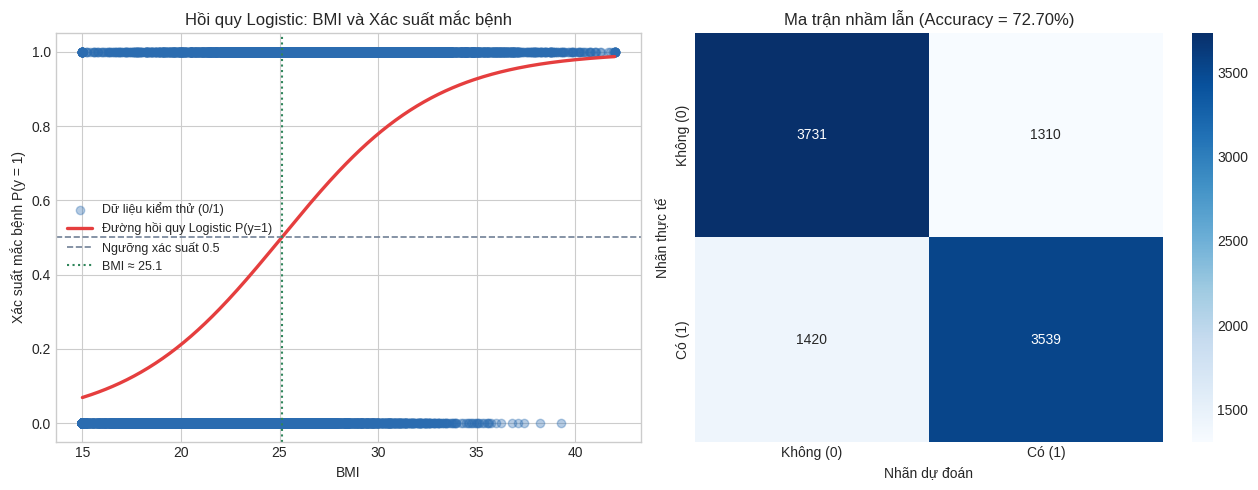

In [15]:
# @title
#bài 2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split

# 1. Tạo dữ liệu mẫu giả lập (BMI càng cao -> xác suất mắc bệnh càng lớn)
rng = np.random.default_rng(42)
n_samples = 50000
bmi = np.clip(rng.normal(loc=25.0, scale=5.5, size=n_samples), 15.0, 42.0)

# Hàm logit: z = -6.5 + 0.26 * BMI -> tại BMI = 25 thì z = 0, p = 0.5
logits = -6.5 + 0.26 * bmi
prob_disease = 1 / (1 + np.exp(-logits))
disease = rng.binomial(1, prob_disease)

df = pd.DataFrame({"BMI": bmi, "Disease": disease})
print("5 dòng dữ liệu đầu tiên:\n", df.head())
print("\nPhân bố nhãn (0: Không bệnh, 1: Mắc bệnh):\n", df["Disease"].value_counts())

# 2. Chia tập dữ liệu: 80% Train - 20% Test
X = df[["BMI"]]  # Ma trận đặc trưng 2 chiều
y = df["Disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Khởi tạo và huấn luyện mô hình Hồi quy Logistic
model = LogisticRegression()
model.fit(X_train, y_train)

w = model.coef_[0][0]
b = model.intercept_[0]
bmi_half = -b / w  # Ngưỡng BMI tại đó xác suất dự đoán P(y=1) = 0.5
print(f"\nPhương trình tuyến tính bên trong: z = {w:.4f} * BMI + ({b:.4f})")
print(f"Ngưỡng BMI tại P(Disease=1) = 0.5: {bmi_half:.2f}")

# 4. Dự đoán xác suất và nhãn trên tập kiểm tra
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

preview_test = pd.DataFrame({
    "BMI": X_test["BMI"].values,
    "Actual (y_test)": y_test.values,
    "Prob_Disease (P=1)": np.round(y_prob, 4),
    "Predicted (y_pred)": y_pred,
})
print("\n10 mẫu dự đoán đầu tiên trên tập kiểm tra:\n", preview_test.head(10))

# 5. Đánh giá hiệu quả mô hình
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"\nĐộ chính xác (Accuracy): {acc:.4f} ({acc*100:.2f}%)")
print("Ma trận nhầm lẫn (Confusion Matrix):\n", cm)
print("\nBáo cáo phân loại chi tiết:\n", classification_report(
    y_test, y_pred, target_names=["Không bệnh (0)", "Mắc bệnh (1)"]
))

# 6. Trực quan hóa dữ liệu, đường hồi quy logistic và ma trận nhầm lẫn
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bmi_grid = np.linspace(15, 42, 300).reshape(-1, 1)
prob_grid = model.predict_proba(bmi_grid)[:, 1]

axes[0].scatter(
    X_test["BMI"], y_test, alpha=0.35, color="#2b6cb0", label="Dữ liệu kiểm thử (0/1)"
)
axes[0].plot(
    bmi_grid, prob_grid, color="#e53e3e", linewidth=2.4, label="Đường hồi quy Logistic P(y=1)"
)
axes[0].axhline(0.5, color="#718096", linestyle="--", linewidth=1.2, label="Ngưỡng xác suất 0.5")
axes[0].axvline(
    bmi_half, color="#2f855a", linestyle=":", linewidth=1.5, label=f"BMI ≈ {bmi_half:.1f}"
)
axes[0].set_title("Hồi quy Logistic: BMI và Xác suất mắc bệnh")
axes[0].set_xlabel("BMI")
axes[0].set_ylabel("Xác suất mắc bệnh P(y = 1)")
axes[0].legend(loc="center left", fontsize=9)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Không (0)", "Có (1)"],
    yticklabels=["Không (0)", "Có (1)"],
    ax=axes[1],
)
axes[1].set_title(f"Ma trận nhầm lẫn (Accuracy = {acc*100:.2f}%)")
axes[1].set_xlabel("Nhãn dự đoán")
axes[1].set_ylabel("Nhãn thực tế")

plt.tight_layout()
plt.show()

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

# 1. Đọc & làm sạch dữ liệu
df = pd.read_csv("train.csv").drop_duplicates().copy()
for col in df.select_dtypes(include="object").columns:
  df[col] = df[col].astype(str).str.strip()



In [20]:
# Hiển thị thông tin và 5 dòng đầu của dữ liệu train.csv đã làm sạch (df)
print("Kích thước tập dữ liệu sau khi làm sạch:", df.shape)
display(df.head())

Kích thước tập dữ liệu sau khi làm sạch: (18944, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,52,Private,98926,HS-grad,9,Never-married,Other-service,Unmarried,White,Male,-3,0,44,United-States,<=50K
1,76,Self-emp-not-inc,132607,Bachelors,12,Married-civ-spouse,Sales,Husband,White,Male,7527,0,44,United-States,>50K
2,40,Private,243258,Bachelors,13,Married-civ-spouse,Transport-moving,Husband,Amer-Indian-Eskimo,Male,19,0,57,United-States,>50K
3,76,State-gov,181259,Bachelors,12,Married-civ-spouse,Prof-specialty,Husband,White,Male,7720,0,44,United-States,>50K
4,36,Self-emp-inc,115379,Masters,13,Divorced,Exec-managerial,Not-in-family,White,Male,12,0,58,United-States,<=50K


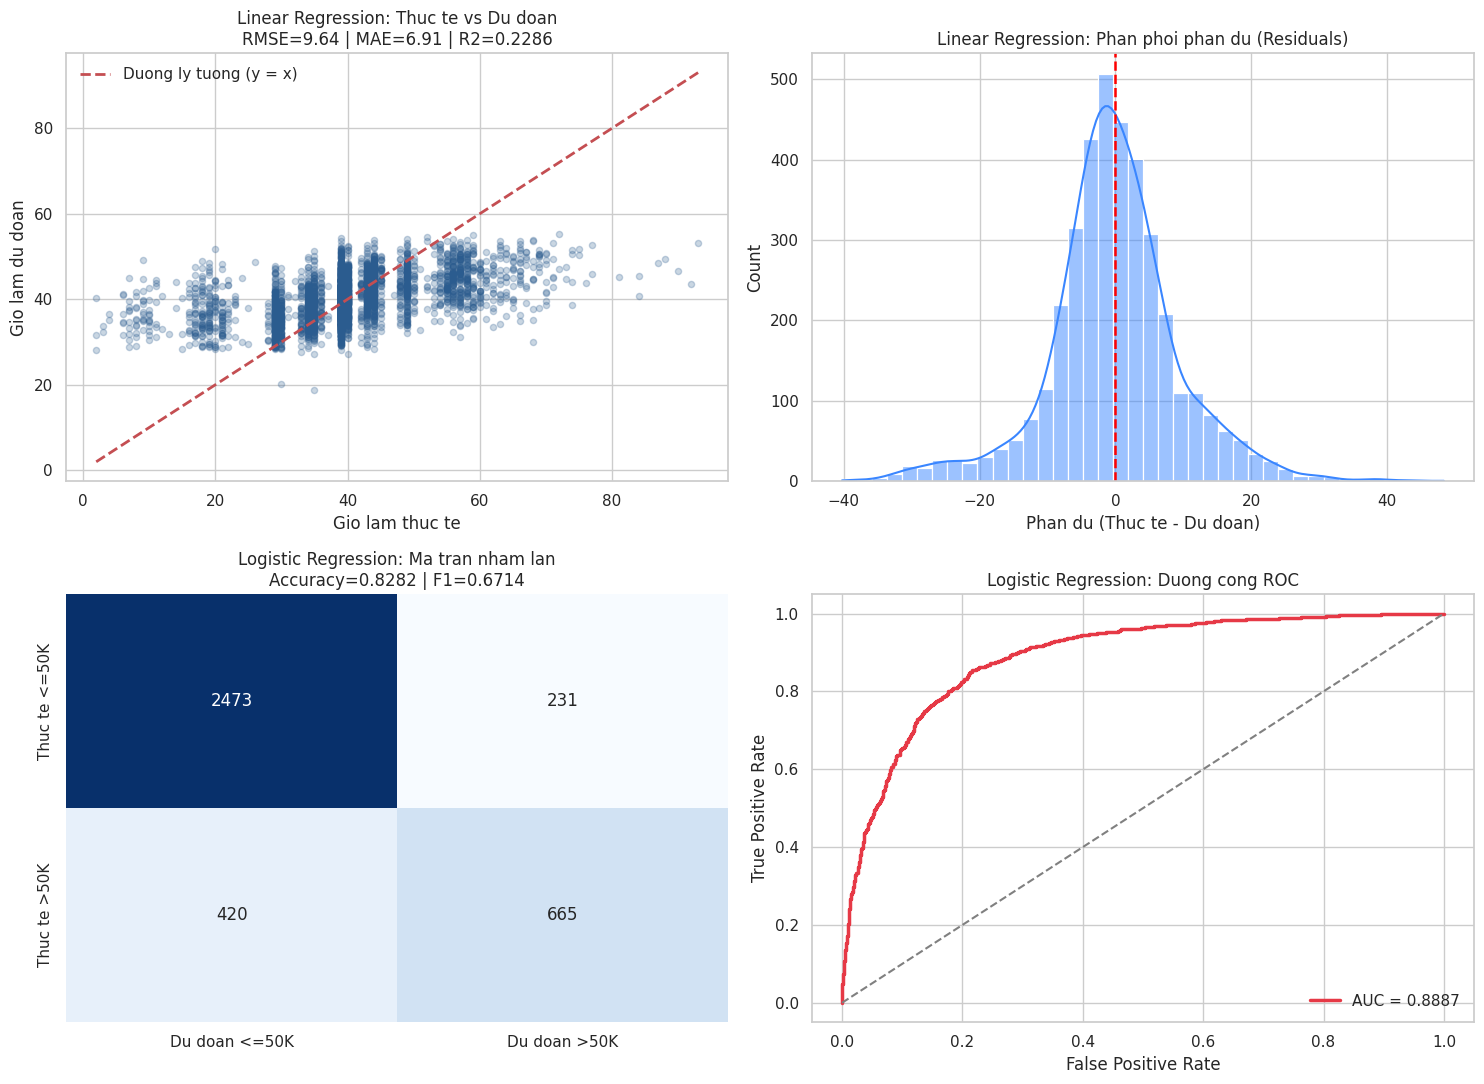

In [21]:
# --- MÔ HÌNH 1: LINEAR REGRESSION (hours-per-week) ---
y_lin = df["hours-per-week"]
X_lin = df.drop(columns=["hours-per-week"])

Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_lin, y_lin, test_size=0.2, random_state=42
)

prep_lin = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        X_lin.select_dtypes(include=["int64", "float64"]).columns.tolist(),
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        X_lin.select_dtypes(include=["object"]).columns.tolist(),
    ),
])

lin_pipe = Pipeline([("prep", prep_lin), ("reg", LinearRegression())])
lin_pipe.fit(Xl_train, yl_train)
yl_pred = lin_pipe.predict(Xl_test)

rmse_lin = np.sqrt(mean_squared_error(yl_test, yl_pred))
mae_lin = mean_absolute_error(yl_test, yl_pred)
r2_lin = r2_score(yl_test, yl_pred)

# --- MÔ HÌNH 2: LOGISTIC REGRESSION (income >50K) ---
y_log = (df["income"] == ">50K").astype(int)
X_log = df.drop(columns=["income"])

Xg_train, Xg_test, yg_train, yg_test = train_test_split(
    X_log, y_log, test_size=0.2, random_state=42, stratify=y_log
)

prep_log = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        X_log.select_dtypes(include=["int64", "float64"]).columns.tolist(),
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        X_log.select_dtypes(include=["object"]).columns.tolist(),
    ),
])

log_pipe = Pipeline([
    ("prep", prep_log),
    ("clf", LogisticRegression(C=0.1, max_iter=1000, random_state=42)),
])
log_pipe.fit(Xg_train, yg_train)
yg_pred = log_pipe.predict(Xg_test)
yg_proba = log_pipe.predict_proba(Xg_test)[:, 1]

acc_log = accuracy_score(yg_test, yg_pred)
f1_log = f1_score(yg_test, yg_pred)
auc_log = roc_auc_score(yg_test, yg_proba)

# --- TRỰC QUAN HÓA ---
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Biểu đồ 1: Actual vs Predicted (Linear Regression)
axes[0, 0].scatter(yl_test, yl_pred, alpha=0.25, color="#2b5c8f", s=20)
lims = [min(yl_test.min(), yl_pred.min()), max(yl_test.max(), yl_pred.max())]
axes[0, 0].plot(lims, lims, "r--", lw=2, label="Duong ly tuong (y = x)")
axes[0, 0].set_title(
    f"Linear Regression: Thuc te vs Du doan\nRMSE={rmse_lin:.2f} |"
    f" MAE={mae_lin:.2f} | R2={r2_lin:.4f}"
)
axes[0, 0].set_xlabel("Gio lam thuc te")
axes[0, 0].set_ylabel("Gio lam du doan")
axes[0, 0].legend()

# Biểu đồ 2: Residuals Distribution (Linear Regression)
sns.histplot(yl_test - yl_pred, bins=40, kde=True, color="#3a86ff", ax=axes[0, 1])
axes[0, 1].axvline(0, color="red", linestyle="--", lw=1.8)
axes[0, 1].set_title("Linear Regression: Phan phoi phan du (Residuals)")
axes[0, 1].set_xlabel("Phan du (Thuc te - Du doan)")

# Biểu đồ 3: Confusion Matrix (Logistic Regression)
cm = confusion_matrix(yg_test, yg_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[1, 0],
    xticklabels=["Du doan <=50K", "Du doan >50K"],
    yticklabels=["Thuc te <=50K", "Thuc te >50K"],
)
axes[1, 0].set_title(
    f"Logistic Regression: Ma tran nham lan\nAccuracy={acc_log:.4f} |"
    f" F1={f1_log:.4f}"
)

# Biểu đồ 4: ROC Curve (Logistic Regression)
fpr, tpr, _ = roc_curve(yg_test, yg_proba)
axes[1, 1].plot(
    fpr, tpr, color="#e63946", lw=2.5, label=f"AUC = {auc_log:.4f}"
)
axes[1, 1].plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1.5)
axes[1, 1].set_title("Logistic Regression: Duong cong ROC")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [22]:
# Hiển thị các chỉ số đánh giá của từng mô hình trong bài 3
print("=== CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH HỒI QUY TUYẾN TÍNH (LINEAR REGRESSION) ===")
print(f"RMSE (Root Mean Squared Error): {rmse_lin:.4f}")
print(f"MAE (Mean Absolute Error)     : {mae_lin:.4f}")
print(f"R2 Score (Hệ số xác định)      : {r2_lin:.4f} ({r2_lin*100:.2f}%)")

print("\n=== CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH HỒI QUY LOGISTIC (LOGISTIC REGRESSION) ===")
print(f"Accuracy (Độ chính xác)       : {acc_log:.4f} ({acc_log*100:.2f}%)")
print(f"F1-Score                      : {f1_log:.4f}")
print(f"AUC (Area Under ROC Curve)    : {auc_log:.4f}")

=== CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH HỒI QUY TUYẾN TÍNH (LINEAR REGRESSION) ===
RMSE (Root Mean Squared Error): 9.6408
MAE (Mean Absolute Error)     : 6.9104
R2 Score (Hệ số xác định)      : 0.2286 (22.86%)

=== CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH HỒI QUY LOGISTIC (LOGISTIC REGRESSION) ===
Accuracy (Độ chính xác)       : 0.8282 (82.82%)
F1-Score                      : 0.6714
AUC (Area Under ROC Curve)    : 0.8887


I. CÁC BIỂU ĐỒ TRỰC QUAN HÓA (4 biểu đồ trong một khung hình)
1. Biểu đồ 1 (Góc trên - Trái): Actual vs Predicted (Thực tế so với Dự đoán)
Mô tả: Biểu diễn tương quan giữa số giờ làm thực tế của mỗi người (Trục X) và số giờ làm do mô hình Hồi quy tuyến tính dự đoán (Trục Y).
Ý nghĩa:
Đường nét đứt màu đỏ ($y=x$) là Đường lý tưởng, đại diện cho kịch bản dự đoán chính xác tuyệt đối.
Các chấm tròn màu xanh dương đại diện cho dữ liệu kiểm thử. Hiện tại các chấm xanh phân tán thành các dải dọc khá rộng và lệch xa khỏi đường màu đỏ. Điều này chỉ ra rằng ở cùng một mức giờ làm thực tế (ví dụ: 40 giờ), mô hình lại đưa ra các mức dự báo dao động rất khác nhau, thể hiện độ chính xác của mô hình ở mức vừa phải.
2. Biểu đồ 2 (Góc trên - Phải): Residuals Distribution (Phân phối phần dư)
Mô tả: Thể hiện phân phối tần suất của sai số (Phần dư = Giá trị thực tế - Giá trị dự đoán).
Ý nghĩa:
Đường nét đứt màu đỏ nằm tại điểm 0. Nếu mô hình dự đoán hoàn hảo, toàn bộ phần dư sẽ tập trung ngay tại điểm 0 này.
Đỉnh của phân phối nằm rất gần vạch 0, cho thấy mô hình không bị lệch (bias) quá nhiều về một phía. Tuy nhiên, sai số vẫn phân tán rộng sang hai bên từ $-20$đến $+20$ giờ, phản ánh mức độ dao động thực tế của số giờ làm việc.
3. Biểu đồ 3 (Góc dưới - Trái): Confusion Matrix (Ma trận nhầm lẫn)
Mô tả: Bảng thống kê kết quả phân loại thu nhập của mô hình Hồi quy Logistic.
Ý nghĩa:
Ô góc trên - trái (2473): Số người thu nhập $\le 50K$được dự đoán chính xác là $\le 50K$(True Negative).
Ô góc dưới - phải (665): Số người thu nhập $>50K$ được dự đoán chính xác là $>50K$ (True Positive).
Ô góc trên - phải (231): Số người thực tế $\le 50K$ nhưng bị dự đoán nhầm thành $>50K$ (False Positive).
Ô góc dưới - trái (420): Số người thực tế $>50K$ nhưng bị dự đoán nhầm thành $\le 50K$ (False Negative).
Đánh giá: Số lượng đoán đúng chiếm đa số vượt trội so với số lượng đoán sai, chứng minh mô hình phân loại rất hiệu quả.
4. Biểu đồ 4 (Góc dưới - Phải): ROC Curve (Đường cong ROC)
Mô tả: Thể hiện khả năng phân biệt giữa 2 nhóm thu nhập của mô hình khi thay đổi ngưỡng phân loại.
Ý nghĩa:
Đường cong màu đỏ càng uốn sát về góc trên cùng bên trái thì mô hình càng tốt.
Chỉ số AUC = 0.8887 (gần 0.90) là một con số xuất sắc, chứng minh mô hình có khả năng phân biệt cực kỳ nhạy bén giữa người thu nhập cao và người thu nhập thấp.\
II. CÁC CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH
1. Mô hình Hồi quy tuyến tính (Linear Regression)
RMSE (Root Mean Squared Error) = 9.6408:
Ý nghĩa: Độ lệch trung bình (theo khoảng cách hình học) giữa số giờ làm việc thực tế và dự đoán là khoảng 9.64 giờ/tuần.
MAE (Mean Absolute Error) = 6.9104:
Ý nghĩa: Sai lệch tuyệt đối trung bình là khoảng 6.91 giờ/tuần.
$R^2$ Score (Hệ số xác định) = 0.2286 (22.86%):
Ý nghĩa: Các thuộc tính đầu vào (như tuổi, trình độ, nghề nghiệp,...) giải thích được 22.86% sự biến động về số giờ làm việc của một người. 77.14% còn lại do các yếu tố cá nhân ngoài mô hình quyết định.
2. Mô hình Hồi quy Logistic (Logistic Regression)
Accuracy (Độ chính xác) = 82.82%:
Ý nghĩa: Trong 100 người được đưa vào kiểm thử, mô hình dự đoán chính xác phân khúc thu nhập cho khoảng 83 người.
F1-Score = 0.6714:
Ý nghĩa: Chỉ số cân bằng hài hòa giữa độ chính xác dự báo (Precision) và khả năng tìm kiếm (Recall) đối với nhóm người có thu nhập cao ($>50K$). Con số 0.6714 cho thấy mô hình hoạt động khá ổn định, không bị thiên lệch quá đà.